In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
pumpkins = pd.read_csv('US-pumpkins.csv')
pumpkins = pumpkins[pumpkins['Package'].str.contains('bushel', case=True, regex=True)]

pumpkins.head()

,City Name,Type,Package,Variety,Sub Variety,Grade,Date,Low Price,High Price,Mostly Low,...,Unit of Sale,Quality,Condition,Appearance,Storage,Crop,Repack,Trans Mode,Unnamed: 24,Unnamed: 25
70,BALTIMORE,NaN,1 1/9 bushel cartons,PIE TYPE,NaN,NaN,9/24/16,15.0,15.0,15.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
71,BALTIMORE,NaN,1 1/9 bushel cartons,PIE TYPE,NaN,NaN,9/24/16,18.0,18.0,18.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
72,BALTIMORE,NaN,1 1/9 bushel cartons,PIE TYPE,NaN,NaN,10/1/16,18.0,18.0,18.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
73,BALTIMORE,NaN,1 1/9 bushel cartons,PIE TYPE,NaN,NaN,10/1/16,17.0,17.0,17.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
74,BALTIMORE,NaN,1 1/9 bushel cartons,PIE TYPE,NaN,NaN,10/8/16,15.0,15.0,15.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN


In [8]:
columns_to_select = ['Package', 'Low Price', 'High Price', 'Date']
pumpkins = pumpkins.loc[:, columns_to_select]

price = (pumpkins['Low Price'] + pumpkins['High Price']) / 2

month = pd.DatetimeIndex(pumpkins['Date']).month
new_pumpkins = pd.DataFrame({'Month': month, 'Package': pumpkins['Package'], 'Low Price': pumpkins['Low Price'],'High Price': pumpkins['High Price'], 'Price': price})
new_pumpkins.loc[new_pumpkins['Package'].str.contains('1 1/9'), 'Price'] = price/(1 + 1/9)
new_pumpkins.loc[new_pumpkins['Package'].str.contains('1/2'), 'Price'] = price/(1/2)


new_pumpkins.head()

,Month,Package,Low Price,High Price,Price
70,9,1 1/9 bushel cartons,15.0,15.0,13.5
71,9,1 1/9 bushel cartons,18.0,18.0,16.2
72,10,1 1/9 bushel cartons,18.0,18.0,16.2
73,10,1 1/9 bushel cartons,17.0,17.0,15.3
74,10,1 1/9 bushel cartons,15.0,15.0,13.5


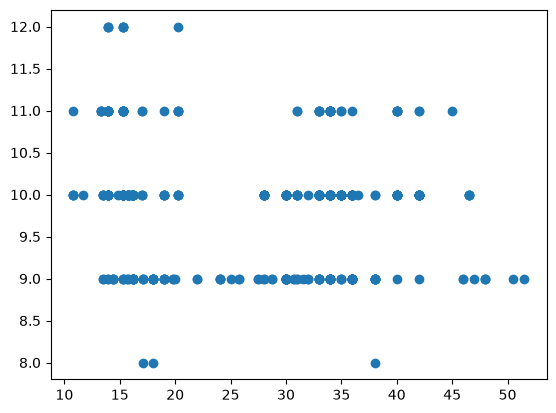

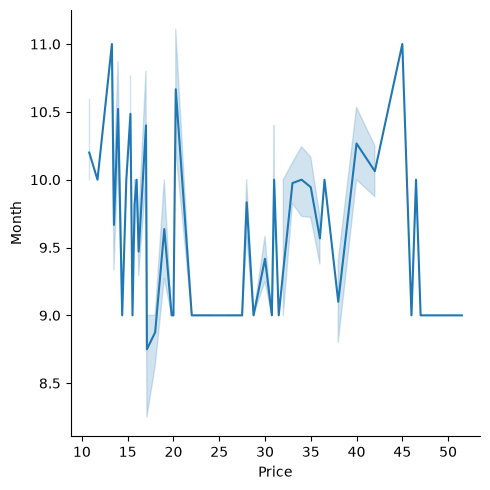

In [9]:
price = new_pumpkins.Price
month = new_pumpkins.Month
plt.scatter(price, month)
plt.show()

sns.relplot(x="Price", y="Month", kind="line", data=new_pumpkins)

Text(0, 0.5, 'Pumpkin Price')

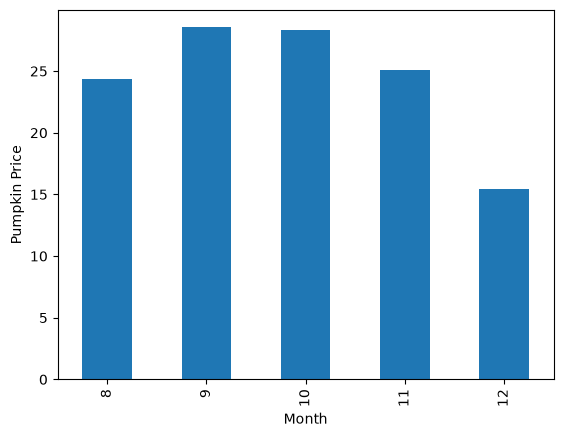

In [10]:
new_pumpkins.groupby(['Month'])['Price'].mean().plot(kind='bar')
plt.ylabel("Pumpkin Price")

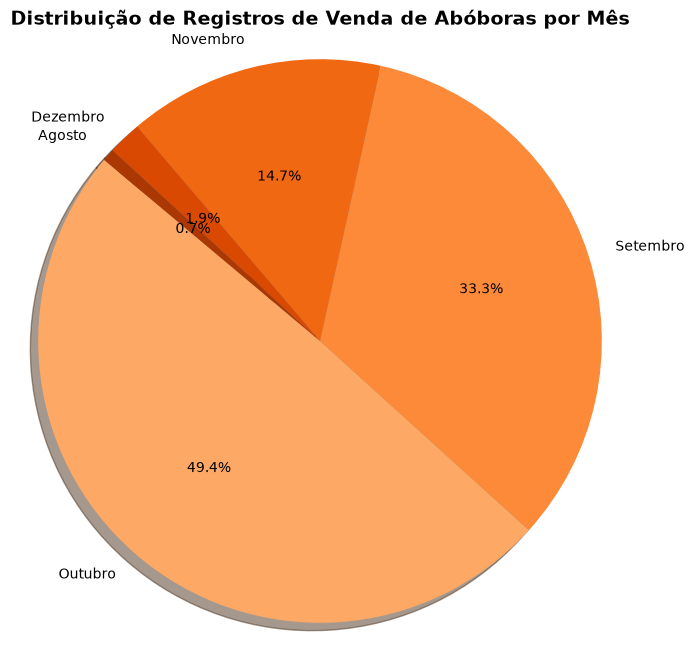

In [11]:
"ATIVIDADE grafico em pizza"

import matplotlib.pyplot as plt

# 1. Agrupar e contar a quantidade de registros por Mês
month_counts = new_pumpkins['Month'].value_counts()

# Mapeamento opcional para exibir os nomes dos meses em vez dos números
month_names = {8: 'Agosto', 9: 'Setembro', 10: 'Outubro', 11: 'Novembro', 12: 'Dezembro'}
labels = [month_names.get(m, f'Mês {m}') for m in month_counts.index]

# 2. Configurar a figura do gráfico
plt.figure(figsize=(8, 8))

# 3. Criar o gráfico de pizza
plt.pie(
    month_counts, 
    labels=labels, 
    autopct='%1.1f%%',       # Exibe a porcentagem com 1 casa decimal
    startangle=140,           # Ângulo inicial para melhor disposição
    shadow=True,              # Adiciona uma sombra leve
    colors=plt.cm.Oranges(range(100, 250, 30)) # Tons de laranja (combinando com abóboras!)
)

# 4. Título e exibição
plt.title('Distribuição de Registros de Venda de Abóboras por Mês', fontsize=14, fontweight='bold')
plt.axis('equal') # Garante que a pizza seja desenhada como um círculo
plt.show()

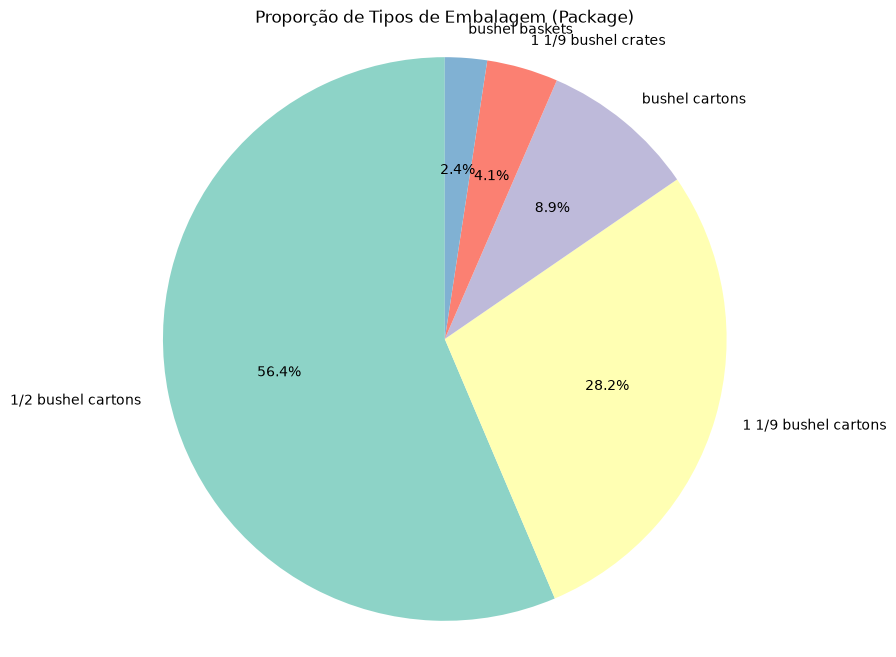

In [12]:
package_counts = new_pumpkins['Package'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    package_counts, 
    labels=package_counts.index, 
    autopct='%1.1f%%', 
    startangle=90,
    colors=plt.cm.Set3.colors
)
plt.title('Proporção de Tipos de Embalagem (Package)')
plt.axis('equal')
plt.show()